# Comparação de Paradigmas de Despacho sob Captação Imperfeita de Demanda

**Projeto de Pesquisa Operacional — notebook único, didático e reprodutível.**

Este notebook compara empiricamente três paradigmas de despacho de recursos sob
**captação imperfeita de demanda** (parte da demanda real nunca é observada no
momento da decisão):

1. **Predict-then-Optimize (PTO)** — previsão + otimização matemática;
2. **Reinforcement Learning (RL)** — política sequencial aprendida por reforço;
3. **MIP/Online** — programação inteira mista com reotimização em *rolling horizon*.

> **Pergunta científica.** Sob captação imperfeita, qual paradigma entrega maior
> **disponibilidade** (fração da demanda **real** atendida) e como cada um degrada
> quando a confiabilidade da captação cai?

O notebook é executável de cima para baixo em um ambiente limpo. As primeiras
células concentram configuração e utilitários; o corpo do notebook permanece enxuto.

## Seção 0 — Configuração, dependências e utilitários

Centralizamos aqui: imports, detecção de solver MIP (Gurobi → CBC), sementes,
parâmetros globais (`CONFIG`) e funções utilitárias reutilizadas pelas seções
seguintes. Nada de lógica de negócio ainda.

In [1]:
from __future__ import annotations

import os
import time
import math
import json
import warnings
import urllib.request
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

sns.set_theme(context="notebook", style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

print("Ambiente numérico carregado.")
print(f"  numpy  {np.__version__}")
print(f"  pandas {pd.__version__}")

Ambiente numérico carregado.
  numpy  2.0.2
  pandas 3.0.6


In [2]:
# ------------------------------------------------------------------
# Detecção de solver MIP: tenta Gurobi (licença acadêmica/comercial),
# cai para CBC via PuLP automaticamente. O restante do notebook usa
# a função resolve_mip(...) e não precisa saber qual backend está ativo.
# ------------------------------------------------------------------
SOLVER_BACKEND = None  # "gurobi" | "cbc"

try:
    import gurobipy as gp
    from gurobipy import GRB

    # Testa se há licença utilizável criando um modelo trivial.
    _env = gp.Env(empty=True)
    _env.setParam("OutputFlag", 0)
    _env.start()
    _m = gp.Model(env=_env)
    _m.dispose()
    _env.dispose()
    SOLVER_BACKEND = "gurobi"
except Exception as _e:  # pragma: no cover - depende do ambiente
    SOLVER_BACKEND = None

if SOLVER_BACKEND is None:
    import pulp  # fallback garantido
    SOLVER_BACKEND = "cbc"

print(f"Backend de otimização MIP selecionado: {SOLVER_BACKEND.upper()}")

Backend de otimização MIP selecionado: GUROBI


In [3]:
# ------------------------------------------------------------------
# Reprodutibilidade: semente global única propagada a numpy e torch.
# ------------------------------------------------------------------
GLOBAL_SEED = 42

def set_global_seed(seed: int = GLOBAL_SEED) -> None:
    import random as _random
    _random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.use_deterministic_algorithms(False)
    except Exception:
        pass

set_global_seed()
print(f"Semente global fixada em {GLOBAL_SEED}.")

Semente global fixada em 42.


In [4]:
# ------------------------------------------------------------------
# CONFIG: parâmetros globais do estudo. Um único ponto de verdade.
# ------------------------------------------------------------------
@dataclass
class Config:
    # --- Dados ---
    data_url: str = ("https://d37ci6vzurychx.cloudfront.net/trip-data/"
                     "yellow_tripdata_2024-01.parquet")
    data_dir: Path = Path("data")
    data_file: str = "yellow_tripdata_2024-01.parquet"

    # --- Escopo espaço-temporal ---
    n_zones: int = 10            # top-N zonas por volume
    step_minutes: int = 15       # granularidade da decisão
    steps_per_day: int = field(init=False)

    # --- Split temporal (por blocos de dias) ---
    train_days: int = 14
    val_days: int = 7
    test_days: int = 7

    # --- Recursos / capacidade (calibrados a partir dos dados) ---
    fleet_K: int = field(default=0)      # preenchido na calibração
    service_c: int = field(default=0)    # preenchido na calibração
    oracle_target: float = 0.88          # disponibilidade-alvo do oráculo

    # --- Penalidades do objetivo (default: foco em disponibilidade pura) ---
    lambda_idle: float = 0.0
    lambda_repos: float = 0.0

    # --- MIP/Online ---
    horizon_H: int = 4           # janelas à frente no rolling horizon
    mip_timeout_s: float = 5.0   # timeout por reotimização

    # --- RL ---
    rl_episodes: int = 300
    rl_gamma: float = 0.95
    rl_lr: float = 1e-3

    def __post_init__(self):
        self.steps_per_day = (24 * 60) // self.step_minutes
        self.data_dir = Path(self.data_dir)

CONFIG = Config()
CONFIG.data_dir.mkdir(parents=True, exist_ok=True)
print("CONFIG inicializado:")
for k, v in asdict(CONFIG).items():
    print(f"  {k:16s} = {v}")

CONFIG inicializado:
  data_url         = https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet
  data_dir         = data
  data_file        = yellow_tripdata_2024-01.parquet
  n_zones          = 10
  step_minutes     = 15
  steps_per_day    = 96
  train_days       = 14
  val_days         = 7
  test_days        = 7
  fleet_K          = 0
  service_c        = 0
  oracle_target    = 0.88
  lambda_idle      = 0.0
  lambda_repos     = 0.0
  horizon_H        = 4
  mip_timeout_s    = 5.0
  rl_episodes      = 300
  rl_gamma         = 0.95
  rl_lr            = 0.001


In [5]:
# ------------------------------------------------------------------
# Utilitários de métrica e avaliação (reutilizados por todos os paradigmas).
# ------------------------------------------------------------------
def availability(D: np.ndarray, A: np.ndarray, c: int) -> float:
    '''Disponibilidade = sum(min(D, c*A)) / sum(D).

    D : demanda REAL (ground truth), shape (T, Z)
    A : veículos alocados, shape (T, Z)
    c : capacidade de serviço por veículo
    '''
    served = np.minimum(D, c * A).sum()
    total = D.sum()
    return float(served / total) if total > 0 else 1.0


def served_units(D: np.ndarray, A: np.ndarray, c: int) -> np.ndarray:
    return np.minimum(D, c * A)


def idle_capacity(D: np.ndarray, A: np.ndarray, c: int) -> float:
    '''Capacidade ociosa total: c*A - demanda atendida (>= 0).'''
    return float(np.clip(c * A - D, 0, None).sum())


def objective_value(D, A, c, lam_idle=0.0, lam_repos=0.0):
    '''Objetivo comum (maximização) usado na AVALIAÇÃO a posteriori.'''
    served = served_units(D, A, c).sum()
    idle = np.clip(c * A - D, 0, None).sum()
    repos = np.abs(np.diff(A, axis=0)).sum() if A.shape[0] > 1 else 0.0
    return float(served - lam_idle * idle - lam_repos * repos)


print("Utilitários de métrica definidos: availability, served_units, "
      "idle_capacity, objective_value.")

Utilitários de métrica definidos: availability, served_units, idle_capacity, objective_value.


## Seção 1 — Definição formal do problema

### 1.1 Entidades, recursos e horizonte

- **Zonas** $z \in Z$, $|Z| = N$ (top-$N$ *taxi zones* de Manhattan por volume).
- **Recurso**: frota de $K$ veículos homogêneos, realocáveis a cada passo.
- **Capacidade de serviço** $c$: cada veículo atende até $c$ unidades de demanda por passo.
- **Horizonte**: dia dividido em $T$ passos de $\Delta t$ (padrão 15 min, $T = 96$).
- **Decisão**: no início de cada passo $t$, escolher $a_{z,t} \in \mathbb{Z}_{\ge 0}$
  (veículos na zona $z$), com $\sum_z a_{z,t} \le K$.

### 1.2 Processos (separação explícita — anti-vazamento)

| Símbolo | Significado | Disponível na decisão? |
|---------|-------------|------------------------|
| $D_{z,t}$ | **demanda real** (ground truth) | ❌ só na avaliação |
| $O_{z,t}$ | **demanda observada** (captada) | ✅ até $t-1$ |
| $\mathcal{I}_t$ | informação disponível em $t$ | ✅ (histórico de $O$ + calendário) |

A captação imperfeita filtra a demanda real:
$$ O_{z,t} = \sum_{i=1}^{D_{z,t}} \mathbb{1}[u_i < p^{capt}_{z,t}], \quad u_i \sim \mathcal{U}(0,1). $$

### 1.3 Métrica principal — disponibilidade

$$ \text{Disponibilidade} = \frac{\sum_{z,t} \min(D_{z,t},\, c\,a_{z,t})}{\sum_{z,t} D_{z,t}} \in [0,1]. $$

É a fração da **demanda real** atendida. **Crucial**: o numerador usa $D$ (avaliação
*a posteriori*), mas a decisão $a_{z,t}$ só pode depender de $\mathcal{I}_t$.

### 1.4 Função objetivo comum

$$
\max_{a} \; \underbrace{\sum_{z,t} \min(D_{z,t}, c\,a_{z,t})}_{\text{demanda atendida}}
\; - \; \lambda_{\text{ocioso}} \sum_{z,t} (c\,a_{z,t} - D_{z,t})^+
\; - \; \lambda_{\text{repos}} \sum_{t,z} |a_{z,t} - a_{z,t-1}|
$$

sujeito a $\sum_z a_{z,t} \le K$ e $a_{z,t} \in \mathbb{Z}_{\ge 0}$.
Default $\lambda = 0$ (disponibilidade pura); penalidades entram na análise de sensibilidade.

### 1.5 Papel de cada paradigma

- **PTO**: estima $\hat D_{z,t}$ de $\mathcal{I}_t$, depois resolve o MIP de alocação com $\hat D$.
- **RL**: aprende $\pi(a_t \mid \mathcal{I}_t)$ maximizando recompensa alinhada à disponibilidade.
- **MIP/Online**: resolve MIP em janela $[t, t+H]$ com previsão simples, reotimizando a cada passo.

## Seção 2 — Carga de dados, EDA e simulação da captação imperfeita

Pipeline:
1. **Download/cache** do Parquet do NYC TLC (domínio público).
2. **Agregação** em tensor de demanda real $D \in \mathbb{Z}^{\,\text{dias} \times T \times Z}$.
3. **EDA** rápida (perfil intradiário e por zona).
4. **Gerador de captação imperfeita** configurável (alta/média/baixa; MAR/MNAR).

In [6]:
def download_tlc_data(cfg: Config) -> Path:
    '''Baixa (com cache) o arquivo Parquet do NYC TLC.'''
    dest = cfg.data_dir / cfg.data_file
    if dest.exists() and dest.stat().st_size > 0:
        print(f"[cache] usando {dest} ({dest.stat().st_size/1e6:.1f} MB)")
        return dest
    print(f"[download] {cfg.data_url}")
    tmp = dest.with_suffix(".tmp")
    urllib.request.urlretrieve(cfg.data_url, tmp)
    tmp.rename(dest)
    print(f"[ok] salvo em {dest} ({dest.stat().st_size/1e6:.1f} MB)")
    return dest


raw_path = download_tlc_data(CONFIG)

[download] https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet


[ok] salvo em data\yellow_tripdata_2024-01.parquet (50.0 MB)


In [7]:
def load_and_aggregate(path: Path, cfg: Config) -> tuple[np.ndarray, list[int], pd.DatetimeIndex]:
    '''Lê o Parquet e agrega em tensor de demanda real D[dia, passo, zona].

    Retorna:
      D      : np.ndarray int, shape (n_days, steps_per_day, n_zones)
      zones  : lista de LocationIDs selecionados (top-N por volume)
      days   : DatetimeIndex com as datas (eixo 0 de D)
    '''
    cols = ["tpep_pickup_datetime", "PULocationID"]
    df = pd.read_parquet(path, columns=cols)
    df = df.rename(columns={"tpep_pickup_datetime": "ts", "PULocationID": "zone"})

    # Mantém apenas o mês de referência (remove timestamps espúrios do TLC).
    ref = df["ts"].dt.to_period("M").mode().iloc[0]
    df = df[df["ts"].dt.to_period("M") == ref].copy()

    # Top-N zonas por volume total.
    top = df["zone"].value_counts().head(cfg.n_zones).index.tolist()
    top = sorted(top)
    df = df[df["zone"].isin(top)].copy()
    zone_to_idx = {z: i for i, z in enumerate(top)}

    # Índices temporais: dia e passo intradiário.
    df["date"] = df["ts"].dt.normalize()
    minutes = df["ts"].dt.hour * 60 + df["ts"].dt.minute
    df["step"] = (minutes // cfg.step_minutes).astype(int)
    df["zidx"] = df["zone"].map(zone_to_idx).astype(int)

    days = pd.DatetimeIndex(sorted(df["date"].unique()))
    day_to_idx = {d: i for i, d in enumerate(days)}
    df["didx"] = df["date"].map(day_to_idx).astype(int)

    D = np.zeros((len(days), cfg.steps_per_day, cfg.n_zones), dtype=np.int32)
    np.add.at(D, (df["didx"].values, df["step"].values, df["zidx"].values), 1)

    print(f"Tensor de demanda real D: shape {D.shape} "
          f"(dias={D.shape[0]}, passos/dia={D.shape[1]}, zonas={D.shape[2]})")
    print(f"Total de corridas agregadas: {D.sum():,}")
    return D, top, days


D_real, ZONES, DAYS = load_and_aggregate(raw_path, CONFIG)

Tensor de demanda real D: shape (31, 96, 10) (dias=31, passos/dia=96, zonas=10)
Total de corridas agregadas: 1,167,527


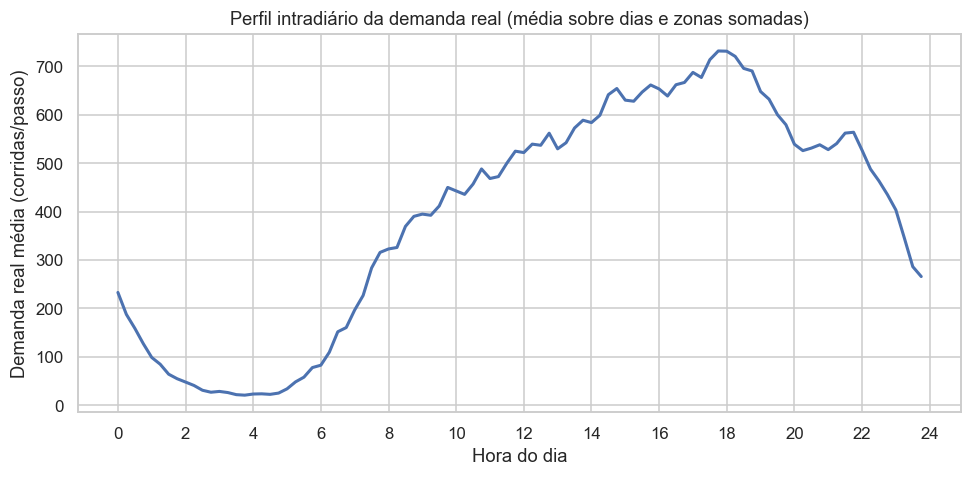

In [8]:
# --- EDA 1: perfil intradiário médio (soma nas zonas, média nos dias) ---
intraday = D_real.sum(axis=2).mean(axis=0)  # shape (steps_per_day,)
hours = np.arange(CONFIG.steps_per_day) * CONFIG.step_minutes / 60.0

fig, ax = plt.subplots()
ax.plot(hours, intraday, lw=2)
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Demanda real média (corridas/passo)")
ax.set_title("Perfil intradiário da demanda real (média sobre dias e zonas somadas)")
ax.set_xticks(range(0, 25, 2))
plt.tight_layout(); plt.show()

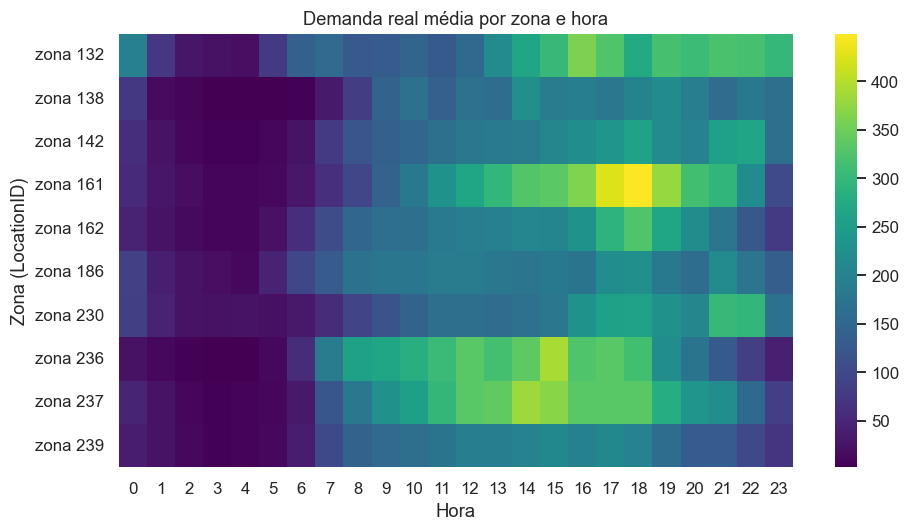

In [9]:
# --- EDA 2: heatmap zona x hora (demanda média) ---
by_zone_hour = D_real.mean(axis=0)  # (steps, zones)
# agrega passos em horas para leitura
steps_per_hour = 60 // CONFIG.step_minutes
hourly = by_zone_hour.reshape(24, steps_per_hour, CONFIG.n_zones).sum(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(hourly.T, cmap="viridis", ax=ax,
            xticklabels=range(24),
            yticklabels=[f"zona {z}" for z in ZONES])
ax.set_xlabel("Hora"); ax.set_ylabel("Zona (LocationID)")
ax.set_title("Demanda real média por zona e hora")
plt.tight_layout(); plt.show()

### 2.1 Gerador de captação imperfeita

Modelamos a probabilidade de captação por passo/zona com uma sigmoide sobre
covariáveis, permitindo mecanismos **MAR** (depende de hora/zona observáveis) e
**MNAR** (depende da própria carga real — picos subcaptados):

$$
p^{capt}_{z,t} = \sigma\!\big(\beta_0 + \beta_{\text{hora}}(t) + \beta_{\text{zona}}(z)
+ \gamma \cdot \tilde D_{z,t}\big),
$$

onde $\tilde D$ é a carga real normalizada e $\gamma \neq 0$ ativa o componente MNAR.
O intercepto $\beta_0$ é **calibrado** para atingir a captação média alvo do cenário.

In [10]:
@dataclass
class CaptureScenario:
    name: str
    target_mean: float   # captação média desejada
    beta_hour_amp: float # amplitude da dependência horária (MAR)
    beta_zone_amp: float # amplitude da dependência por zona (MAR)
    gamma_mnar: float    # peso do componente MNAR (<=0 subcapta picos)
    noise_sd: float      # ruído logit


SCENARIOS = {
    "alta":  CaptureScenario("alta",  0.90, 0.25, 0.20,  0.00, 0.05),
    "media": CaptureScenario("media", 0.65, 0.60, 0.50, -0.40, 0.15),
    "baixa": CaptureScenario("baixa", 0.40, 0.90, 0.70, -1.20, 0.30),
}


def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def build_capture_prob(D: np.ndarray, sc: CaptureScenario, cfg: Config,
                       seed: int = GLOBAL_SEED) -> np.ndarray:
    '''Constrói p_capt[dia, passo, zona] para um cenário, calibrando beta0
    para que a média (ponderada pela demanda) fique ~ target_mean.'''
    rng = np.random.default_rng(seed)
    n_days, T, Z = D.shape

    # Componente horário (padrão senoidal) e por zona (fixo por zona).
    hour_frac = (np.arange(T) / T) * 2 * np.pi
    beta_hour = sc.beta_hour_amp * np.sin(hour_frac - np.pi / 3)      # (T,)
    beta_zone = sc.beta_zone_amp * rng.standard_normal(Z)            # (Z,)

    # Carga real normalizada por (passo,zona) -> componente MNAR.
    Dz = D.astype(float)
    denom = Dz.max() if Dz.max() > 0 else 1.0
    load_norm = Dz / denom

    noise = sc.noise_sd * rng.standard_normal(D.shape)

    logit_base = (beta_hour[None, :, None]
                  + beta_zone[None, None, :]
                  + sc.gamma_mnar * load_norm
                  + noise)

    # Calibra beta0 por busca binária para atingir a captação média alvo
    # (ponderada pela demanda, que é o que de fato importa operacionalmente).
    w = Dz / Dz.sum()
    lo, hi = -10.0, 10.0
    for _ in range(60):
        b0 = 0.5 * (lo + hi)
        p = _sigmoid(b0 + logit_base)
        mean_w = float((p * w).sum())
        if mean_w < sc.target_mean:
            lo = b0
        else:
            hi = b0
    p_capt = _sigmoid(b0 + logit_base)
    return np.clip(p_capt, 1e-4, 1 - 1e-4)


def apply_capture(D: np.ndarray, p_capt: np.ndarray, seed: int = GLOBAL_SEED) -> np.ndarray:
    '''Gera demanda observada O ~ Binomial(D, p_capt). Vetorizado.'''
    rng = np.random.default_rng(seed + 777)
    return rng.binomial(D, p_capt).astype(np.int32)


# Pré-computa p_capt e O para cada cenário (semente fixa -> reprodutível).
P_CAPT, D_OBS = {}, {}
for key, sc in SCENARIOS.items():
    P_CAPT[key] = build_capture_prob(D_real, sc, CONFIG)
    D_OBS[key] = apply_capture(D_real, P_CAPT[key])
    eff = D_OBS[key].sum() / D_real.sum()
    print(f"Cenário {key:5s}: captação média (alvo {sc.target_mean:.2f}) "
          f"-> efetiva {eff:.3f}")

Cenário alta : captação média (alvo 0.90) -> efetiva 0.900
Cenário media: captação média (alvo 0.65) -> efetiva 0.650
Cenário baixa: captação média (alvo 0.40) -> efetiva 0.400


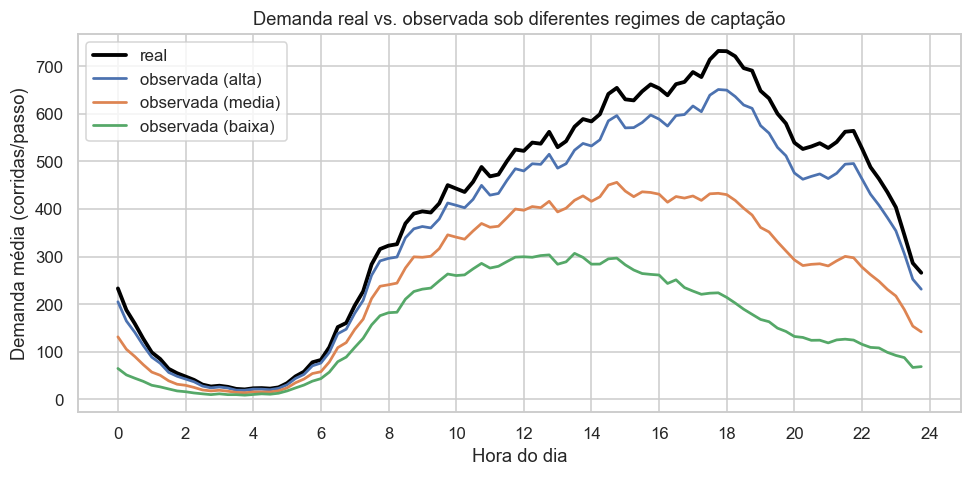

In [11]:
# --- Visualiza o efeito da captação no perfil intradiário ---
fig, ax = plt.subplots()
ax.plot(hours, D_real.sum(axis=2).mean(axis=0), lw=2.5, color="black", label="real")
for key in ["alta", "media", "baixa"]:
    ax.plot(hours, D_OBS[key].sum(axis=2).mean(axis=0), lw=1.8, label=f"observada ({key})")
ax.set_xlabel("Hora do dia"); ax.set_ylabel("Demanda média (corridas/passo)")
ax.set_title("Demanda real vs. observada sob diferentes regimes de captação")
ax.legend(); ax.set_xticks(range(0, 25, 2))
plt.tight_layout(); plt.show()

## Seção 3 — Ambiente de simulação comum e baselines

Todos os paradigmas atuam sobre o **mesmo** ambiente, garantindo comparação justa.
O ambiente expõe a um controlador apenas a informação legítima em cada passo
($\mathcal{I}_t$) e avalia a decisão contra a demanda **real**.

### 3.1 Contrato do ambiente

- `reset(day)` → estado inicial do dia.
- `observe()` → $\mathcal{I}_t$ (histórico de observadas + calendário). **Nunca** $D_{\ge t}$.
- `step(a_t)` → aplica alocação, revela $D_{\cdot,t}$ **apenas para registro/avaliação**,
  avança o relógio e devolve recompensa = demanda atendida no passo.

### 3.2 Split temporal

Blocos contíguos de dias (sem embaralhar): treino → validação → teste.

In [12]:
def make_temporal_split(n_days: int, cfg: Config) -> dict[str, np.ndarray]:
    '''Divide os dias em blocos contíguos treino/val/teste (sem shuffle).'''
    idx = np.arange(n_days)
    tr = idx[: cfg.train_days]
    va = idx[cfg.train_days: cfg.train_days + cfg.val_days]
    te = idx[cfg.train_days + cfg.val_days:
             cfg.train_days + cfg.val_days + cfg.test_days]
    split = {"train": tr, "val": va, "test": te}
    for k, v in split.items():
        print(f"  {k:5s}: {len(v)} dias -> índices {v[:3]}{'...' if len(v) > 3 else ''}")
    return split


SPLIT = make_temporal_split(D_real.shape[0], CONFIG)

  train: 14 dias -> índices [0 1 2]...
  val  : 7 dias -> índices [14 15 16]...
  test : 7 dias -> índices [21 22 23]...


In [13]:
class DispatchEnv:
    '''Ambiente de despacho para um único dia.

    Expõe apenas informação legítima no instante da decisão. A demanda real é
    usada somente para computar recompensa/avaliação APÓS a ação (sem vazamento).

    Parâmetros
    ----------
    D_real_day : (T, Z) demanda real do dia (ground truth).
    D_obs_day  : (T, Z) demanda observada do dia (captação imperfeita).
    cfg        : Config.
    '''

    def __init__(self, D_real_day: np.ndarray, D_obs_day: np.ndarray, cfg: Config):
        self.Dr = D_real_day
        self.Do = D_obs_day
        self.cfg = cfg
        self.T, self.Z = D_real_day.shape
        self.reset()

    def reset(self):
        self.t = 0
        self.alloc_hist = np.zeros((self.T, self.Z), dtype=np.int32)
        self.prev_alloc = np.zeros(self.Z, dtype=np.int32)
        return self.observe()

    def observe(self) -> dict:
        '''Informação disponível no instante t (I_t): histórico de OBSERVADAS
        até t-1, índice do passo e alocação anterior. Nunca demanda real futura.'''
        obs_hist = self.Do[: self.t]  # observadas de 0..t-1
        return {
            "t": self.t,
            "T": self.T,
            "step_of_day": self.t,
            "obs_history": obs_hist,
            "last_obs": self.Do[self.t - 1] if self.t > 0 else np.zeros(self.Z, int),
            "prev_alloc": self.prev_alloc.copy(),
        }

    def step(self, a_t: np.ndarray):
        '''Aplica alocação a_t no passo atual. Retorna (obs, reward, done, info).

        reward = demanda REAL atendida no passo (alinhada à disponibilidade).
        '''
        a_t = np.asarray(a_t, dtype=np.int32)
        assert a_t.shape == (self.Z,), f"ação deve ter shape ({self.Z},)"
        assert a_t.sum() <= self.cfg.fleet_K + 1e-9, "viola capacidade da frota K"

        d_now = self.Dr[self.t]  # revelado SÓ agora, para avaliação
        served = np.minimum(d_now, self.cfg.service_c * a_t)
        reward = float(served.sum())

        # penalidades opcionais
        idle = np.clip(self.cfg.service_c * a_t - d_now, 0, None).sum()
        repos = np.abs(a_t - self.prev_alloc).sum()
        reward -= self.cfg.lambda_idle * idle + self.cfg.lambda_repos * repos

        self.alloc_hist[self.t] = a_t
        self.prev_alloc = a_t
        self.t += 1
        done = self.t >= self.T
        info = {"served": float(served.sum()), "demand": float(d_now.sum()),
                "idle": float(idle), "repos": float(repos)}
        return (self.observe() if not done else None), reward, done, info


print("Classe DispatchEnv definida (ambiente comum a todos os paradigmas).")

Classe DispatchEnv definida (ambiente comum a todos os paradigmas).


In [14]:
def run_policy_on_days(policy: Callable[[dict, Config], np.ndarray],
                       D_real_sel: np.ndarray, D_obs_sel: np.ndarray,
                       cfg: Config) -> dict:
    '''Executa uma política sobre um conjunto de dias e agrega métricas.

    policy(obs, cfg) -> vetor de alocação a_t (shape (Z,)), com sum <= K.
    Retorna dict com tensores de alocação e métricas operacionais/computacionais.
    '''
    n_days = D_real_sel.shape[0]
    A_all = np.zeros_like(D_real_sel)
    t0 = time.perf_counter()
    decide_times = []

    for d in range(n_days):
        env = DispatchEnv(D_real_sel[d], D_obs_sel[d], cfg)
        obs = env.reset()
        done = False
        while not done:
            td = time.perf_counter()
            a_t = policy(obs, cfg)
            decide_times.append(time.perf_counter() - td)
            obs, _, done, _ = env.step(a_t)
        A_all[d] = env.alloc_hist

    wall = time.perf_counter() - t0
    avail = availability(D_real_sel, A_all, cfg.service_c)
    return {
        "alloc": A_all,
        "availability": avail,
        "idle": idle_capacity(D_real_sel, A_all, cfg.service_c),
        "objective": objective_value(D_real_sel, A_all, cfg.service_c,
                                     cfg.lambda_idle, cfg.lambda_repos),
        "wall_time_s": wall,
        "mean_decision_ms": float(np.mean(decide_times) * 1000),
    }


print("Runner run_policy_on_days definido.")

Runner run_policy_on_days definido.


### 3.3 Calibração da frota

Escolhemos $K$ e $c$ de modo que o **oráculo** (informação perfeita de $D$) atinja a
disponibilidade-alvo (`oracle_target`), deixando folga para os paradigmas se
diferenciarem. Fixamos $c$ e buscamos o menor $K$ que atinge o alvo com a política
oráculo (alocação proporcional ótima à demanda real, respeitando $K$).

In [15]:
def waterfill_alloc(demand_units: np.ndarray, K: int, c: int) -> np.ndarray:
    '''Aloca K veículos para maximizar demanda atendida dado 'demand_units'
    por zona (guloso ótimo: cada veículo vai onde o ganho marginal é maior).

    Como a cobertura por veículo é c e o ganho é min(demanda_restante, c),
    o guloso por maior demanda residual é ótimo para este subproblema separável.
    '''
    Z = len(demand_units)
    a = np.zeros(Z, dtype=np.int32)
    residual = demand_units.astype(float).copy()
    for _ in range(int(K)):
        z = int(np.argmax(residual))
        if residual[z] <= 0:
            break  # sem ganho marginal -> parar (evita ociosidade)
        a[z] += 1
        residual[z] -= c
    return a


print("Função de alocação gulosa ótima (waterfill) definida. "
      "O oráculo é avaliado diretamente sobre o tensor real em evaluate_oracle.")

Função de alocação gulosa ótima (waterfill) definida. O oráculo é avaliado diretamente sobre o tensor real em evaluate_oracle.


In [16]:
# O oráculo precisa ver a demanda real do passo. Em vez de burlar o env,
# executamos o oráculo diretamente sobre o tensor real (limite superior teórico).
def evaluate_oracle(D_real_sel: np.ndarray, cfg: Config) -> dict:
    n_days, T, Z = D_real_sel.shape
    A = np.zeros_like(D_real_sel)
    for d in range(n_days):
        for t in range(T):
            A[d, t] = waterfill_alloc(D_real_sel[d, t], cfg.fleet_K, cfg.service_c)
    return {"alloc": A, "availability": availability(D_real_sel, A, cfg.service_c)}


def calibrate_fleet(D_real_sel: np.ndarray, cfg: Config,
                    c_candidates=(2, 3, 4, 5)) -> tuple[int, int, float]:
    '''Busca (K, c) tal que o oráculo ~ oracle_target. Para cada c, acha o
    menor K (busca binária) que atinge o alvo; escolhe o par mais 'apertado'.'''
    peak = D_real_sel.sum(axis=2).max()  # pico de demanda total num passo
    best = None
    for c in c_candidates:
        lo, hi = 1, int(math.ceil(peak / c)) + 5
        while lo < hi:
            mid = (lo + hi) // 2
            cfg.fleet_K, cfg.service_c = mid, c
            av = evaluate_oracle(D_real_sel, cfg)["availability"]
            if av >= cfg.oracle_target:
                hi = mid
            else:
                lo = mid + 1
        cfg.fleet_K, cfg.service_c = lo, c
        av = evaluate_oracle(D_real_sel, cfg)["availability"]
        cand = (lo, c, av)
        if best is None or lo < best[0]:
            best = cand
    return best


# Calibra usando os dias de treino (evita olhar o teste).
_K, _c, _av = calibrate_fleet(D_real[SPLIT["train"]], CONFIG)
CONFIG.fleet_K, CONFIG.service_c = _K, _c
print(f"Frota calibrada: K={_K} veículos, c={_c} unidades/veículo "
      f"-> oráculo (treino) = {_av:.3f} disponibilidade")

oracle_test = evaluate_oracle(D_real[SPLIT['test']], CONFIG)
print(f"Oráculo no TESTE: disponibilidade = {oracle_test['availability']:.3f} "
      f"(teto superior de referência)")

Frota calibrada: K=101 veículos, c=5 unidades/veículo -> oráculo (treino) = 0.881 disponibilidade
Oráculo no TESTE: disponibilidade = 0.852 (teto superior de referência)


In [17]:
# --- Baseline ingênua: aloca proporcional à ÚLTIMA demanda OBSERVADA ---
def naive_policy(obs: dict, cfg: Config) -> np.ndarray:
    '''Política ingênua: usa a última demanda observada como proxy e faz
    waterfill. Representa 'reagir ao que se enxerga', sem correção de captação.'''
    last = obs["last_obs"].astype(float)
    if last.sum() <= 0:
        # sem histórico: distribui uniformemente
        a = np.zeros(cfg.n_zones, dtype=np.int32)
        a[: cfg.fleet_K] = 1 if cfg.fleet_K <= cfg.n_zones else 0
        base, rem = divmod(cfg.fleet_K, cfg.n_zones)
        a = np.full(cfg.n_zones, base, dtype=np.int32)
        a[:rem] += 1
        return a
    return waterfill_alloc(last, cfg.fleet_K, cfg.service_c)


# Avalia baseline ingênua no teste, para cada cenário de captação.
print("Baseline ingênua (teste), por cenário de captação:")
baseline_naive = {}
for key in ["alta", "media", "baixa"]:
    res = run_policy_on_days(naive_policy,
                             D_real[SPLIT["test"]], D_OBS[key][SPLIT["test"]],
                             CONFIG)
    baseline_naive[key] = res
    print(f"  {key:5s}: disponibilidade={res['availability']:.3f} "
          f"| decisão={res['mean_decision_ms']:.3f} ms")

Baseline ingênua (teste), por cenário de captação:
  alta : disponibilidade=0.785 | decisão=0.107 ms


  media: disponibilidade=0.673 | decisão=0.084 ms
  baixa: disponibilidade=0.440 | decisão=0.056 ms
